In [2]:
import torch
import matplotlib.pyplot as plt
%matplotlib inline
words = open('../names.txt', 'r').read().splitlines()

In [3]:
char = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(char)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
itos

{1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z',
 0: '.'}

In [4]:
# now our bigram was only looking at the previous character and predicting the next word which shows that we were not getting efficient names
# so now we will implement multilayer perceptron (MLP) where the context will increase to more than 1 character

block_size = 3 # context length: how many characters do we take to predict the next one
X, Y = [], []
for w in words:
    #print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        #print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix] #crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [5]:
C = torch.randn((27, 2))
C[torch.tensor([5,6,7,7,7,7])] # same way we can index X
emb = C[X]
emb.shape  # (32, 3, 2) -> 32 examples, 3 context length, 2 embedding dimension(or the number of features we want to use to represent each character)


torch.Size([228146, 3, 2])

In [6]:
W1 = torch.randn((6, 100)) # 6 input size = 3 context length * 2 embedding dimension and 100 is the number of neurons in the hidden layer
b1 = torch.randn(100)
# cannot do emb @ W1 + b1 because the shape of emb is (32, 3, 2) and W1 is (6, 100) so we will have to reshape emb to (32, 6) and then we can do the matrix multiplication
# so we use torch.cat to concatenate the 3 context length and 2 embedding dimension to get a shape of (32, 6)

torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], dim=1).shape # dim=1 means we are concatenating along the columns.
#doing this along the column for larger context length not possible so we will use torch.unbind to unbind the 3 context length and then we can concatenate them along the columns

torch.cat(torch.unbind(emb, dim=1), dim=1).shape # unbind will return a tuple of 3 tensors of shape (32, 2) and then we can concatenate them along the columns to get a shape of (32, 6)

torch.Size([228146, 6])

In [7]:
# A more efficient way to do this is to use the view method to reshape the tensor. 
# The view method returns a new tensor with the same data as the original tensor but with a different shape. 
# this will reshape the tensor to (32, 6) and we can do the matrix multiplication with W1 and b1
h = emb.view(emb.shape[0], -1) @ W1 + b1 # -1 means that we want to infer the size of that dimension based on the other dimensions.
# and hardcoding the size of the first dimension to 32 is not a good idea because we want to be able to change the batch size later on.
# and torch.cat creates a new memory allocation and copies the data from the original tensor to the new tensor which is not efficient. so view is the way to go.
h.shape

torch.Size([228146, 100])

In [8]:
W2 = torch.randn((100, 27)) # 100 is the previous layer size i.e input for this layer and 27 is the output size i.e number of classes
b2 = torch.randn(27)
logits = h @ W2 + b2

In [9]:
counts = logits.exp() # exponentiate the logits to get positive values
probs = counts / counts.sum(1, keepdims=True) # normalize the counts to get probabilities
# now to get the loss we will use negative log likelihood loss function which is the same as cross entropy loss function
loss = -probs[torch.arange(logits.shape[0]), Y].log().mean() # its like -(1/m) * sum over m (log(probability of the correct class))

#better way would be to use torch.nn.functional.cross_entropy which combines log_softmax and nll_loss in one function
loss = torch.nn.functional.cross_entropy(logits, Y) # this will do the same thing as above but in a more efficient way
loss

tensor(46.4055)

prod level code below stay away dangerous 

In [10]:
#making training set, validation set and test set
def build_dataset(words, block_size=4):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix] #crop and append
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(f"X.shape: {X.shape}, Y.shape: {Y.shape}")
    return X, Y
import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xv, Yv = build_dataset(words[n1:n2]) # 10% after training set
Xt, Yt = build_dataset(words[n2:]) # 10% after validation set

X.shape: torch.Size([182625, 4]), Y.shape: torch.Size([182625])
X.shape: torch.Size([22655, 4]), Y.shape: torch.Size([22655])
X.shape: torch.Size([22866, 4]), Y.shape: torch.Size([22866])


In [11]:
# now combining all the above steps!
block_size = 4
embedding_size = 10
hidden_size = 400
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((len(stoi), embedding_size), generator=g)
W1 = torch.randn((block_size * embedding_size, hidden_size), generator=g) * 0.1
# making the weights smaller by multiplying with 0.1 to avoid exploding gradients and high loss at the start of training
# same with bias we set it to zero because we want the initial output to be zero and then the model will learn to adjust the bias during training
#b1 = torch.zeros(hidden_size)
W2 = torch.randn((hidden_size, len(stoi)), generator=g) * 0.1
b2 = torch.zeros(len(stoi))      


# for batchnormalization we take the h and normalize it by subtracting the mean and dividing by the standard deviation,
# and then we multiply it by a learnable parameter gamma and add a learnable parameter beta. z = gamma * (h - mean) / std + beta. 

gamma = torch.ones((1, hidden_size))  # the gain 
beta = torch.zeros((1, hidden_size)) # and the bias for batch normalization
bnmean_running = torch.zeros((1, hidden_size)) # running mean for batch normalization
bnstd_running = torch.ones((1, hidden_size)) # running std for batch normalization
parameters = [C, W1,  W2, gamma, beta, b2] #removed b1  :/
for p in parameters:
    p.requires_grad_()

don't need to initialize the bias to zero because we will be using batch normalization and there we have beta parameter which will take care of the bias. 
so we can just set it to zero and let the model learn to adjust it during training.

In [12]:
sum(p.numel() for p in [C, W1, b1, W2, b2]) # 27*2 + 6*100 + 100 + 100*27 + 27 = 3,481 parameters

27197

In [13]:
lri = []
lossi = []
stepi = []

In [14]:
# every single iteration is taking a lot of time due to the fact that we are doing in all of the dataset at once, 
# so we will use mini-batch gradient descent to speed up the training process. 
# we will take a random sample of 32 examples from the dataset and do the forward and backward pass on that sample. this will speed up the training process significantly.
for i in range(50000):
    # mini batch
    ix = torch.randint(0, Xtr.shape[0], (64,))
    Xb , Yb = Xtr[ix], Ytr[ix] #batch X, Y of 64 examples from the training set
    # forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 #+ b1
    # right now mainly values are saturated at flat regions near 1 and -1 in tanh so the gradient will be destroyed and the model will not learn anything.
    # so to fix it we can make the weights smaller by multiplying with 0.1 to avoid exploding gradients and high loss at the start of training
    # and instead of multiplying we can use batch normalization to normalize the output of the hidden layer before passing it to the next layer. 
    # this will help in stabilizing the training process and will also help in faster convergence.
    meani, stdi = hpreact.mean(0, keepdim=True), hpreact.std(0, keepdim=True)
    hpreact = gamma * ((hpreact - meani) / stdi) + beta  # network will learn to adjust the gamma and beta parameters during training to scale and shift the normalized output of the hidden layer.
    
    with torch.no_grad():  
        # we multiply by 0.999 and add 0.001 to the running mean and std to give more weight to the previous mean and std and less weight to the current mean and std. 
        # this will help in stabilizing the training process and will also help in faster convergence.
        bnmean_running = 0.999 * bnmean_running + 0.001 * meani
        bnstd_running = 0.999 * bnstd_running + 0.001 * stdi  
    
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    # reg_loss = 1e-4 * (W1.pow(2).mean() + W2.pow(2).mean())  no need for regularization as we are using batch normalization.
    loss = torch.nn.functional.cross_entropy(logits, Ytr[ix]) #+ reg_loss

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    # update parameters
    lr = 0.05 if i < 30000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    stepi.append(i)
    lossi.append(loss.item())

print(loss.item())

1.886153221130371


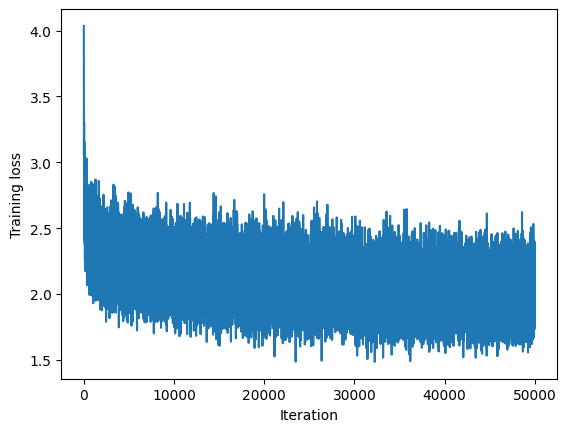

In [15]:
plt.plot(stepi, lossi)
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.show()

In [18]:
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 #+ b1
    # measure mean/std over the entire training set and not just the mini-batch to get a better estimate of the mean and std for inference.
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)
# we don't even need to do this solo we can just update it in the training loop and then use the updated values in the evaluation loop. 
# look above in training with torch.no_grad(). and we have initialized bnmean_running and bnstd_running as zeros and ones respectively 
# because mean will be close to zero and std will be close to one. so we can use these values in the evaluation loop to get the correct loss value.

In [20]:
import torch.nn.functional as F

with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size

        for _ in range(30):  # maximum generated name length
            x = torch.tensor([context])
            emb = C[x]
            embcat = emb.view(emb.shape[0], -1)
            hpreact = embcat @ W1 #+ b1
            mean, std = bnmean_running, bnstd_running
            hpreact = gamma * ((hpreact - mean) / std) + beta
            h = torch.tanh(hpreact)
            logits = h @ W2 + b2

            probs = F.softmax(logits, dim=1)
            ix = torch.multinomial(probs, num_samples=1).item()

            context = context[1:] + [ix]

            if ix == 0:
                break

            out.append(ix)

        print("".join(itos[i] for i in out))

zayla
khakarie
jayonna
eshon
monte
auriella
eileena
kanrie
vivta
jayce
luiressaryama
alman
huxt
kiyah
mayven
beyleigh
yoselix
akaila
lare
oluwa


In [21]:
import torch.nn.functional as F
@torch.no_grad() # disables gradient calculation for the evaluate function to save memory and computations since we are not training the model here and don't need to compute gradients
# as we did batch normalization in the training loop we will also do it in the evaluation loop to get the correct loss value
def evaluate(X, Y):
    with torch.no_grad():
        emb = C[X]
        embcat = emb.view(emb.shape[0], -1)
        hpreact = embcat @ W1 #+ b1
        mean, std = bnmean_running, bnstd_running # use the mean and std calculated from the training set for evaluation
        hpreact = gamma * ((hpreact - mean) / std) + beta
        h = torch.tanh(hpreact)
        logits = h @ W2 + b2
        return F.cross_entropy(logits, Y).item()
print("training loss:", evaluate(Xtr, Ytr))
print("validation loss:", evaluate(Xv, Yv))
print("test loss:", evaluate(Xt, Yt))

training loss: 1.9814658164978027
validation loss: 2.051320791244507
test loss: 2.0464701652526855


In [ ]:
# linear layer -> y = W * A.T + b
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):  # when using batch normalization we don't need bias so thats why option to false it!
        self.weight = torch.randn((fan_in, fan_out)) / fan_in ** 0.5  # in the example above fan_in is block_size * embedding_size and fan_out is hidden_size
        if bias == True: self.bias = torch.zeros(fan_out)  
        else: self.bias = None
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None: self.out += self.bias
        return self.out
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

In [23]:
class BatchNorm1d:
    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # learnable params
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        #running buffers
        self.mean_running = torch.zeros(dim)
        self.var_running = torch.ones(dim)

    def __call__(self, x):
        if self.training is True:  # if training is True then we will calculate the mean and std of the current batch and update the running mean and std
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True) 
        else: #if not training we want to use the running mean and std for inference
            xmean = self.mean_running
            xvar = self.var_running
        xhat = (x - xmean) / (xvar + self.eps) ** 0.5
        self.out = self.gamma * xhat  + self.beta
        if self.training: 
            with torch.no_grad():
                self.mean_running = (1 - self.momentum) * self.mean_running  + self.momentum * xmean
                self.var_running = (1 - self.momentum) * self.var_running + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]



class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []     

# it turns ouut that batch normalization is not very effective for small batch sizes and it is also not very effective for recurrent neural networks. 
# so in prod people use layer normalization instead of batch normalization. Layer normalization normalizes the activations across the features instead of across the batch.
# for it we just need to change the mean and var from mean(0) and std(0) to mean(1) and var(-1, keepdim=True) so it always grabs the last feature dimension even on 3D Transformer tensors
# this is the exact difference between normalizing down the batch column vs. normalizing across each individual example's feature row. And because LayerNorm computes 
# the mean and variance across each single example's features on the fly, it has zero dependency on other examples in the batch—which means you delete self.training, 
# mean_running, and var_running completely.


# also group normalization is also used in prod which normalizes the activations across the groups of features instead of across the batch or across the features.
# still batch normalization is used in prod for convolutional neural networks and fully connected networks.
# and after all this data normalization before training is always important regardless of the normalization technique used in the model.

In [89]:
# now using these classes we will pytorchify and train a model!
embedding_size = 10
hidden_size = 200
C = torch.randn((len(stoi), embedding_size), requires_grad=True)
layers = [
    Linear(block_size * embedding_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, len(stoi), bias=False), BatchNorm1d(len(stoi)),
]
'''
layers = [
    Linear(block_size * embedding_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size),       Tanh(),
    Linear(hidden_size, hidden_size),       Tanh(),
    Linear(hidden_size, hidden_size),       Tanh(),
    Linear(hidden_size, hidden_size),       Tanh(),
    Linear(hidden_size, len(stoi)),]
'''
with torch.no_grad():
    # make last layer smaller so that its not too confident,shrinking the magnitude of the final layer's outputs (the logits) right at the start of training 
    # so that the softmax probabilities aren't overly extreme or saturated
    layers[-1].gamma *= 0.1
    # layers[-1].weight *= 0.1  introduced batchnorm so gamma fix better hehe
    for layer in layers:
        if isinstance(layer, Linear):
            layer.weight *= 5/3 # gain for tanh activation function to avoid saturation of the activation function where it gets stuck at extremes -1 and 1 
# which can cause the gradients to vanish. we want to keep the gradients in a reasonable range. not a problem for relu hehe!
# don't need them when using batch normalization as it will normalize the output of the hidden layer before passing it to the next layer.
# which will help in stablizing the training process and will also help in faster convergence.

parameters = [C] + [p for layer in layers for p in layer.parameters()] 
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
    p.requires_grad = True

175724


In [ ]:
max_steps = 50000
batch_size = 32
lossi = []
ud = [] # used to store the update direction (i.e how much change in the parameters)
torch.set_grad_enabled(True)
for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb , Yb = Xtr[ix], Ytr[ix]
    #forward pass
    emb = C[Xb] #embedding characters into vectors
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x) # take cares of the matrix multiplication and the activation function (tanh in this case) and the batch normalization
    loss = F.cross_entropy(x, Yb)   # x is basically the prediction y_hat and cross_entropy is L = - 1 / m  sum over m(log(softmax(x)))

    #backward pass
    for layer in layers:
        layer.out.retain_grad() # retain the gradient of the output of each layer for backpropagation
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.001
    for p in parameters:
        p.data -= lr * p.grad

    lossi.append(loss.log10().item())
    with torch.no_grad():
        # Calculate the parameter update-to-data ratio on a log scale (std of update / std of params). This helps us understand how much the parameters are changing during training,
        # allowing us to diagnose if the learning rate is too large or too small.
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters]) 
    if i % 10000 == 0:
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    if i > 1000: break

      0/  50000: 1.9459


layer 2 (      Tanh): mean +0.00, std 0.61, saturated 4.08%
layer 5 (      Tanh): mean +0.00, std 0.64, saturated 3.50%
layer 8 (      Tanh): mean +0.00, std 0.65, saturated 3.33%
layer 11 (      Tanh): mean +0.01, std 0.65, saturated 2.77%
layer 14 (      Tanh): mean -0.00, std 0.66, saturated 2.69%


Text(0.5, 1.0, 'activation distribution')

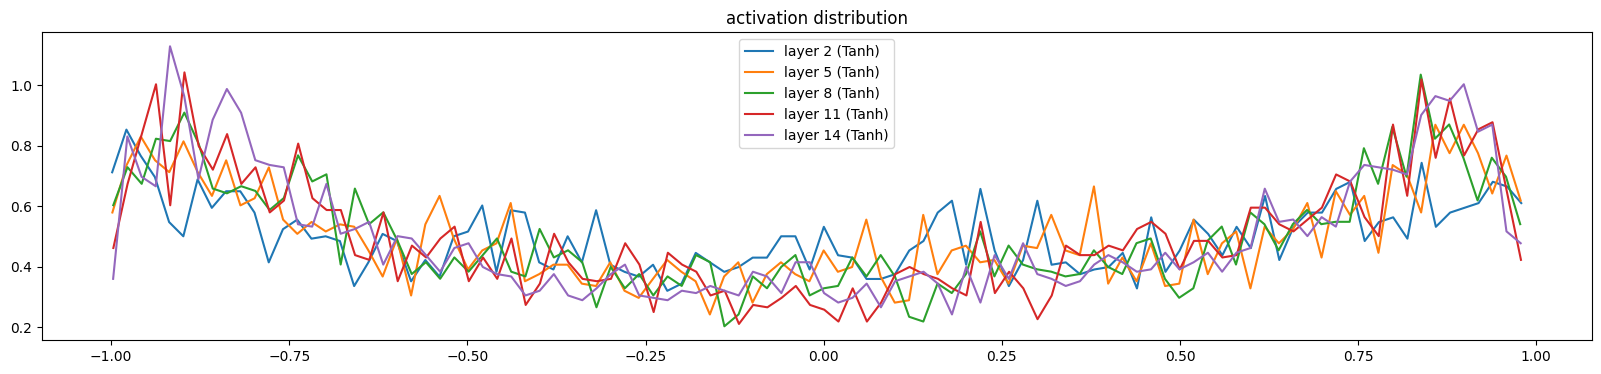

In [108]:
# now visualizing things
# Tanh(z) squashes inputs into a range of [-1, 1]. The derivative (gradient) of Tanh(z) is (1 - tanh^2(z)). 
# If z is too large (positive or negative), Tanh outputs exactly -1 or 1.
# This causes the gradient to become EXACTLY 0, killing backpropagation (Vanishing Gradient).
# We want z to form a clean, stable Gaussian distribution around 0 so the activations 
# fall on the steep, active slope of Tanh where gradients flow freely.

# so we want to see mean close to 0.0, std around 0.6-0.7, saturation close to 0.0% means neurons are active and learning
# what could go wrong 1."U-Shape" or Twin Peaks at -1 and 1: The weights are initialized TOO LARGE. 2. The inputs (z) are pushed to the extreme left/right, causing massive saturation.
# 3. Extreme Spike at 0: The weights are initialized TOO SMALL, means The layer isn't learning anything complex.
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers):
    if isinstance(layer, Tanh):
        t = layer.out
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title("activation distribution")

layer 2 (      Tanh): mean +1.28e-11, std 3.43e-03
layer 5 (      Tanh): mean +5.82e-13, std 3.28e-03
layer 8 (      Tanh): mean -7.57e-12, std 3.40e-03
layer 11 (      Tanh): mean +6.98e-12, std 3.46e-03
layer 14 (      Tanh): mean +1.14e-11, std 3.41e-03


Text(0.5, 1.0, 'gradient distribution')

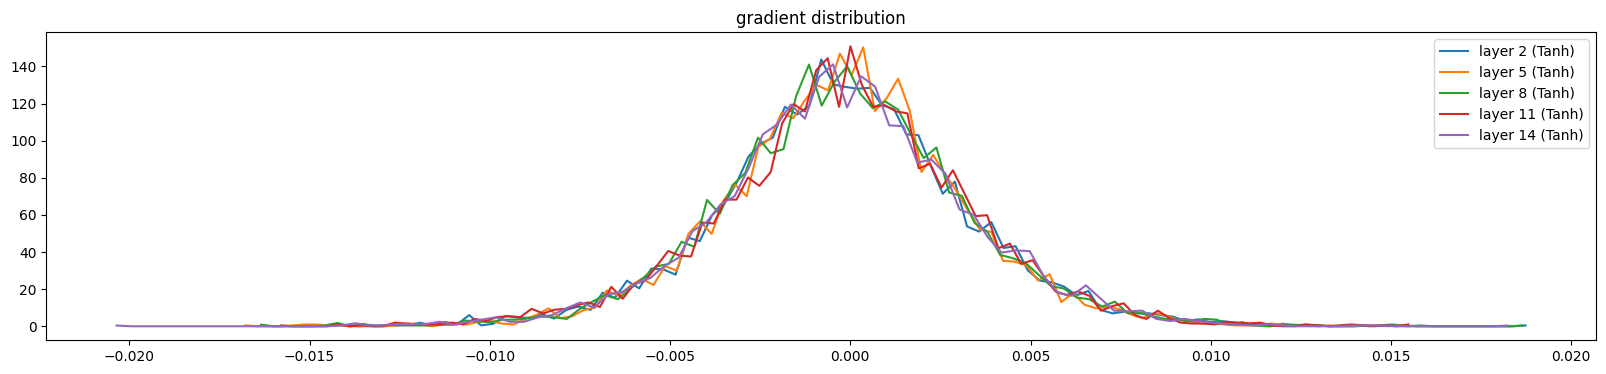

In [109]:
# Gradient distribution of each layer to see if they are vanishing or exploding. we want the gradients to be 
# roughly uniform in scale across all layers so that every layer learns at the same rate.

# we check the mean and std dev here. if the std dev shrinks dramatically as we go from later layers to earlier layers,
# it means gradients are vanishing and early layers won't learn. if it explodes, the optimization breaks.
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers):
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+.2e, std %.2e' % (i, layer.__class__.__name__, t.mean(), t.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach()) # detach() is used to detach the tensor from the computation graph so that it doesn't track gradients.
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title("gradient distribution")

weight   (27, 10) | mean +0.000000 | std 1.635731e-02 || grad:data ratio 1.666355e-02
weight  (40, 200) | mean -0.000003 | std 8.745665e-03 || grad:data ratio 3.298068e-02
weight (200, 200) | mean +0.000136 | std 7.105867e-03 || grad:data ratio 5.898699e-02
weight (200, 200) | mean -0.000009 | std 7.163904e-03 || grad:data ratio 5.965144e-02
weight (200, 200) | mean -0.000002 | std 7.293842e-03 || grad:data ratio 6.103234e-02
weight (200, 200) | mean +0.000035 | std 7.234266e-03 || grad:data ratio 6.053811e-02
weight  (200, 27) | mean -0.000177 | std 2.178676e-02 || grad:data ratio 1.722438e-01


Text(0.5, 1.0, 'weights gradient distribution')

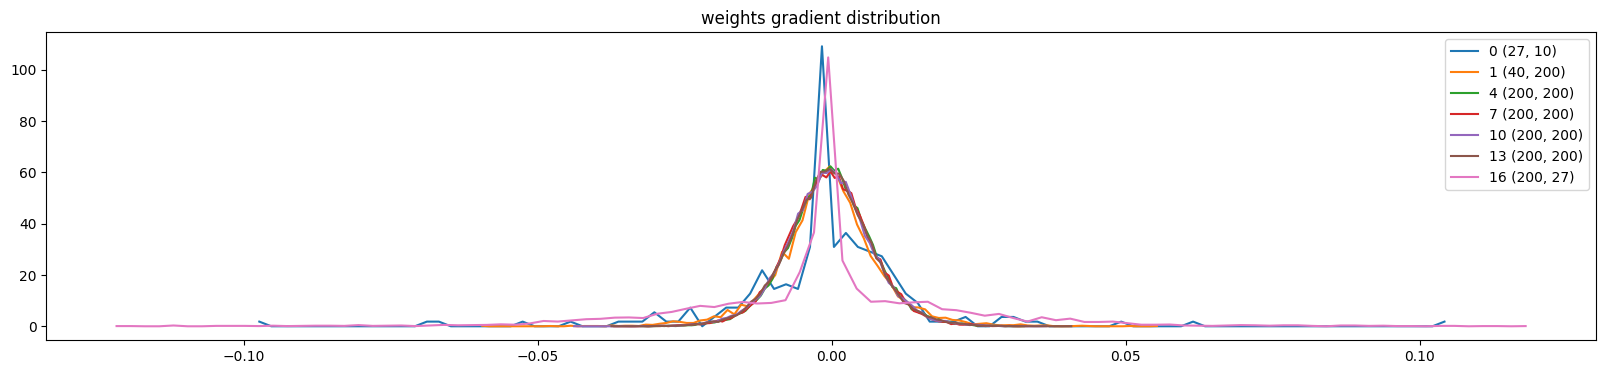

In [110]:
# Parameter gradient distribution and grad:data ratio to see if updates are sized correctly relative to the weights.
# We only inspect 2D tensors (weight matrices) because biases or 1D gain vectors act differently and mask scale changes.

# We compute the grad:data ratio (t.std() / p.std()). If this ratio is too small (e.g., < 1e-4 or 1e-5), the weights are moving too slowly and the model is learning too slowly or frozen. 
# If the ratio is too large, the updates will be too large and the learning step will blow up the weights, reduce learning_rate
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2: # only plot for weight matrices, not biases
        print('weight %10s | mean %+f | std %e || grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution')

Text(0.5, 1.0, 'learning rate update ratio over time')

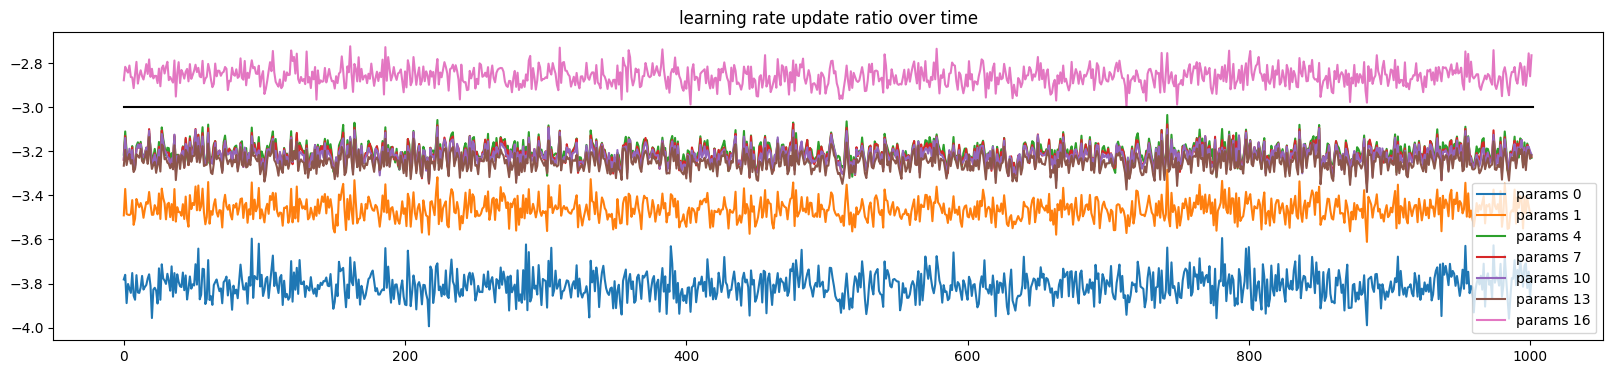

In [111]:
# Learning rate update ratio tracking over time to see if the updates stay stable across training steps.
# We plot the log10 of the actual update ratio for each weight matrix over every single training iteration j.
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append('params %d' % i)
# The black dashed line at y=-3 is our benchmark for a perfect 10^-3 (0.001) learning rate step size.
# If a layer's line drops to -5 or -6, its log updates are too small (frozen) -> Increase the alpha learning rate.
# If it shoots above -2, it's too high. -> Decrease the alpha learning rate.
plt.plot([0, len(ud)], [-3, -3], 'k') # plot a horizontal line at y=-3 to see if the grad:data ratio is too small
plt.legend(legends)
plt.title('learning rate update ratio over time')
# as we can see this and the previous plot are very useful to see if the learning rate is too high or too low and if the model is learning or not.
# and before that we can also see the activation distribution and gradient distribution which helps us change the initialization of the weights and 
# the activation function to avoid saturation and vanishing gradients.

In [112]:
@torch.no_grad()
def evaluate(split):
    x,y = {
    'train': (Xtr, Ytr),
    'val': (Xv, Yv),
    'test': (Xt, Yt),
    }[split]
    emb = C[x]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, y)
    print(split, loss.item())
for layer in layers:
  layer.training = False
evaluate('train')
evaluate('val')
evaluate('test')

train 2.0426950454711914
val 2.096853256225586
test 2.098062038421631


In [115]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      x = emb.view(emb.shape[0], -1) # concatenate the vectors
      for layer in layers:
        x = layer(x)
      logits = x
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

carmah.
amelle.
khilir.
xrey.
caskands.
ejazonte.
delsyn.
jareli.
nellara.
chaiiv.
kaleigh.
ham.
joce.
quintes.
lilea.
jadiq.
watell.
dearyn.
kailee.
dusline.
